In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the dataset provided by teacher
data = pd.read_csv("IMDB Dataset.csv")

print(data.head())
print(data.shape)

                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive
(50000, 2)


In [3]:
X = data["review"].astype(str)
y = data["sentiment"].map({"negative": 0, "positive": 1})

print(X.head())
print(y.head())

0    One of the other reviewers has mentioned that ...
1    A wonderful little production. <br /><br />The...
2    I thought this was a wonderful way to spend ti...
3    Basically there's a family where a little boy ...
4    Petter Mattei's "Love in the Time of Money" is...
Name: review, dtype: object
0    1
1    1
2    1
3    0
4    1
Name: sentiment, dtype: int64


In [4]:
import re
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

def preprocess(text):
    text = re.sub(r"<.*?>", "", text)  # Remove HTML
    text = re.sub(r"[^a-zA-Z\s]", "", text)  # Remove punctuation
    words = text.lower().split()
    words = [word for word in words if word not in ENGLISH_STOP_WORDS]
    return words

sentences = [preprocess(review) for review in X]

print(sentences[0][:20])

['reviewers', 'mentioned', 'watching', 'just', 'oz', 'episode', 'youll', 'hooked', 'right', 'exactly', 'happened', 'methe', 'thing', 'struck', 'oz', 'brutality', 'unflinching', 'scenes', 'violence', 'set']


In [6]:
from gensim.models import Word2Vec

cbow = Word2Vec(
    sentences=sentences,
    vector_size=50,
    window=5,
    min_count=2,
    sg=0,
    epochs=5
)

print("Vocabulary size:", len(cbow.wv))

Vocabulary size: 81274


In [7]:
def get_embedding(words):
    vectors = [cbow.wv[word] for word in words if word in cbow.wv]

    if len(vectors) == 0:
        return np.zeros(50)

    return np.mean(vectors, axis=0)

X_vec = np.array([get_embedding(words) for words in sentences])

print("Embedding shape:", X_vec.shape)

Embedding shape: (50000, 50)


In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_vec, y,
    test_size=0.2,
    random_state=42
)

In [9]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

model = Sequential([
    Dense(64, activation="relu", input_shape=(50,)),
    Dense(32, activation="relu"),
    Dense(1, activation="sigmoid")
])

model.summary()

C:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 64)                  │           3,264 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 5,377 (21.00 KB)

 Trainable params: 5,377 (21.00 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [11]:
history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/5
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8267 - loss: 0.3875 - val_accuracy: 0.8406 - val_loss: 0.3544
Epoch 2/5
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8419 - loss: 0.3563 - val_accuracy: 0.8439 - val_loss: 0.3569
Epoch 3/5
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8450 - loss: 0.3519 - val_accuracy: 0.8416 - val_loss: 0.3624
Epoch 4/5
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8475 - loss: 0.3479 - val_accuracy: 0.8500 - val_loss: 0.3467
Epoch 5/5
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8481 - loss: 0.3454 - val_accuracy: 0.8485 - val_loss: 0.3456


In [12]:
loss, accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8507 - loss: 0.3451
Test Loss: 0.3451327085494995
Test Accuracy: 0.8507000207901001


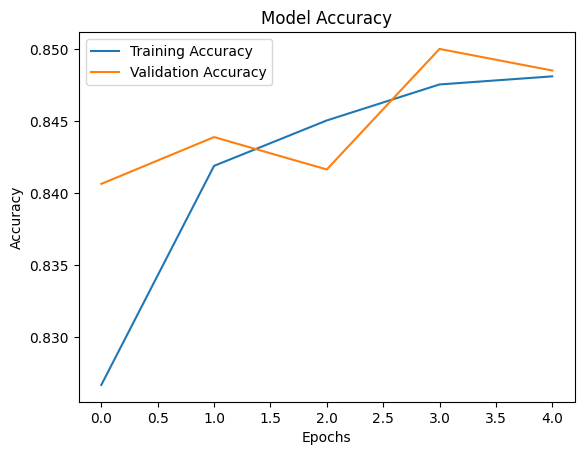

In [13]:
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Model Accuracy")
plt.legend()
plt.show()

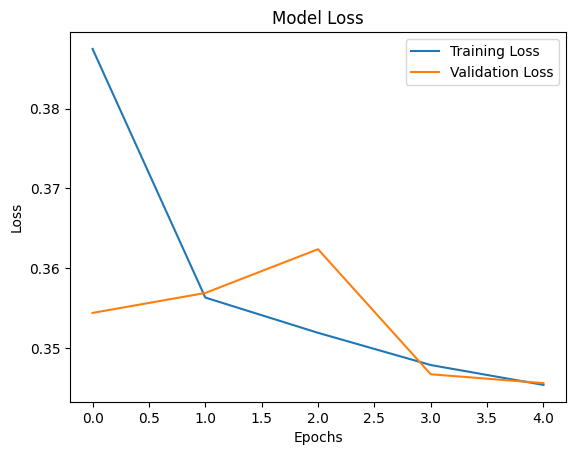

In [14]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Model Loss")
plt.legend()
plt.show()